# Riesgo de construcción: caja, plazo, deuda y dependencia
## Preguntas
¿Cuándo la rentabilidad de un proyecto no evita una ruptura de caja? ¿Cómo cambia el riesgo de cola de una cartera de proyectos con dependencia? Se enlazan cuatro baselines existentes y se examinan sus contratos. Los datos son sintéticos y todas las cantidades monetarias comparten moneda abstracta.

No se afirma haber implementado cada especificación del catálogo. Este notebook demuestra componentes acotados: caja, cronograma, cobertura de deuda y pérdidas crediticias.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


## Implementaciones utilizadas
Se cargan los módulos del proyecto con nombres aislados para que `src` de otros laboratorios no contamine imports. El motor de caja usa un factor común por período: la correlación latente entre shocks de cobros y costos es −w², no −w. No modela por sí solo retrasos contractuales ni persistencia macro.

In [2]:
import importlib.util,sys,csv
ROOT=Path.cwd()
def load(name,path):
    spec=importlib.util.spec_from_file_location(name,path);module=importlib.util.module_from_spec(spec)
    sys.modules[name]=module;spec.loader.exec_module(module);return module
models=load('construction_risk_models',ROOT/'python/src/risk_models.py')
cash=load('construction_cash_model',ROOT/'02-construction-enterprise-risk/01-project-cashflow-at-risk/src/model.py')
project=cash.Project(25.,tuple([20.]*12),tuple([16.]*12),tuple([3.]*12),liquidity_floor=5.)
assert sum(project.monthly_collections)-sum(project.monthly_costs)-sum(project.monthly_debt_service)>0


## Rentable no implica líquido
El mismo proyecto tiene margen acumulado positivo antes de incertidumbre. Se varía la reserva inicial manteniendo cobros, costos, deuda y shocks. Se miden seis semillas con 2.000 escenarios por semilla; la dispersión entre semillas es error de integración, no incertidumbre de calibración.

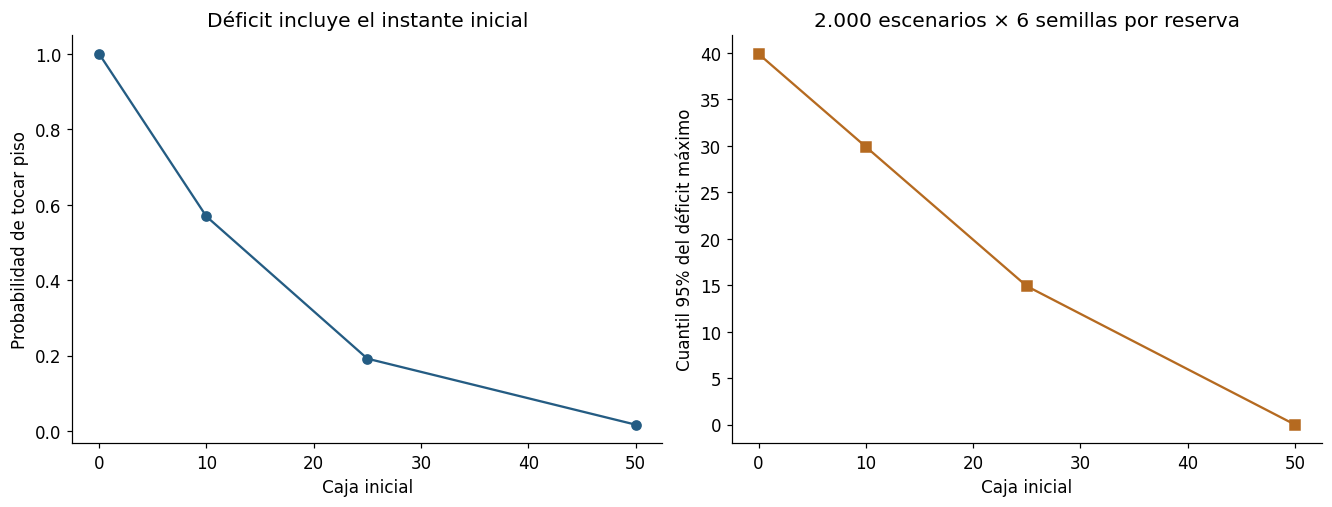

probability_shortfall          ... mean_terminal_cash        
                         mean     std  ...               mean     std
reserve                                ...                           
0.0                    1.0000  0.0000  ...             11.912  0.6103
10.0                   0.5688  0.0114  ...             21.912  0.6103
25.0                   0.1918  0.0097  ...             36.912  0.6103
50.0                   0.0168  0.0021  ...             61.912  0.6103

[4 rows x 8 columns]

In [3]:
cash_rows=[]
for reserve in [0.,10.,25.,50.]:
    for seed in range(6):
        p=cash.Project(reserve,project.monthly_collections,project.monthly_costs,project.monthly_debt_service,5.)
        result=cash.simulate(p,2000,SEED+seed,collection_vol=.25,cost_vol=.20,common_shock_weight=.7)
        cash_rows.append(dict(reserve=reserve,seed=seed,**result))
cash_table=pd.DataFrame(cash_rows)
display(cash_table.groupby('reserve')[['probability_shortfall','expected_peak_shortfall','peak_shortfall_q95','mean_terminal_cash']].agg(['mean','std']).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
summary=cash_table.groupby('reserve').mean(numeric_only=True)
axes[0].plot(summary.index,summary.probability_shortfall,'o-',color='#245C83')
axes[0].set(xlabel='Caja inicial',ylabel='Probabilidad de tocar piso',title='Déficit incluye el instante inicial')
axes[1].plot(summary.index,summary.peak_shortfall_q95,'s-',color='#B56A20')
axes[1].set(xlabel='Caja inicial',ylabel='Cuantil 95% del déficit máximo',title='2.000 escenarios × 6 semillas por reserva')
plt.show()

## Cronograma con rutas alternativas
La duración total es el máximo de sumas por rutas, no la suma de todas las tareas ni el máximo de duraciones individuales. Dos rutas A→B→D y A→C→D pueden intercambiar criticidad. Un calendario determinista con duraciones medias no reproduce necesariamente la esperanza del máximo.

Se simulan duraciones triangulares independientes por tarea; no se confunde triangular con una distribución beta PERT calibrada.

In [4]:
tasks={'A':(1,2,3),'B':(2,3,5),'C':(1,4,8),'D':(1,2,4)}
dependencies={'B':['A'],'C':['A'],'D':['B','C']}
base=models.critical_path({k:(lo+mode+hi)/3 for k,(lo,mode,hi) in tasks.items()},dependencies)
schedule=models.schedule_monte_carlo(tasks,dependencies,n=5000,seed=SEED)
display(pd.DataFrame({'métrica':['CPM con medias de tareas','Duración media simulada','Cuantil duración 95%'],
    'valor':[base['project_duration'],schedule['mean_duration'],schedule['p95_duration']]}))
assert base['project_duration']>=max((lo+mode+hi)/3 for lo,mode,hi in tasks.values())
try:models.critical_path({'A':1,'B':2},{'A':['B'],'B':['A']})
except ValueError:print('Ciclo de dependencias rechazado')
else:raise AssertionError('Se aceptó un cronograma cíclico')

Ciclo de dependencias rechazado


,métrica,valor
0,CPM con medias de tareas,8.666667
1,Duración media simulada,8.910555
2,Cuantil duración 95%,11.380388


## Cobertura de deuda: calendario y denominador
DSCR compara CFADS del período con servicio de ese período. LLCR descuenta CFADS y divide por saldo de deuda. Un período sin servicio no tiene DSCR definido en esta interfaz; no se rellena con cero. El siguiente contraste varía la concentración del servicio, dejando fijo su total.

In [5]:
cfads=[25.,25.,25.,25.];rows=[]
for name,service in [('uniforme',[20,20,20,20]),('adelantado',[50,10,10,10]),('bullet',[0,0,0,80])]:
    result=models.project_finance(cfads,service,80,.10)
    rows.append(dict(schedule=name,dscr=result['dscr'],minimum_dscr=result['minimum_dscr'],llcr=result['llcr']))
display(pd.DataFrame(rows))
assert len({round(row['llcr'],12) for row in rows})==1
print('LLCR igual con el mismo saldo y CFADS; DSCR depende del calendario de servicio.')

LLCR igual con el mismo saldo y CFADS; DSCR depende del calendario de servicio.


,schedule,dscr,minimum_dscr,llcr
0,uniforme,"[1.25, 1.25, 1.25, 1.25]",1.2500,0.990583
1,adelantado,"[0.5, 2.5, 2.5, 2.5]",0.5000,0.990583
2,bullet,"[None, None, None, 0.3125]",0.3125,0.990583


## Dependencia de pérdidas crediticias
El factor latente común tiene correlación ρ entre activos; las probabilidades marginales de default se conservan. Para LGD y EAD fijas, $E[L]=\sum PD_iLGD_iEAD_i$ no depende de ρ, aunque VaR/ES sí. Se contrasta la media simulada con esta identidad y se conserva variación entre semillas.

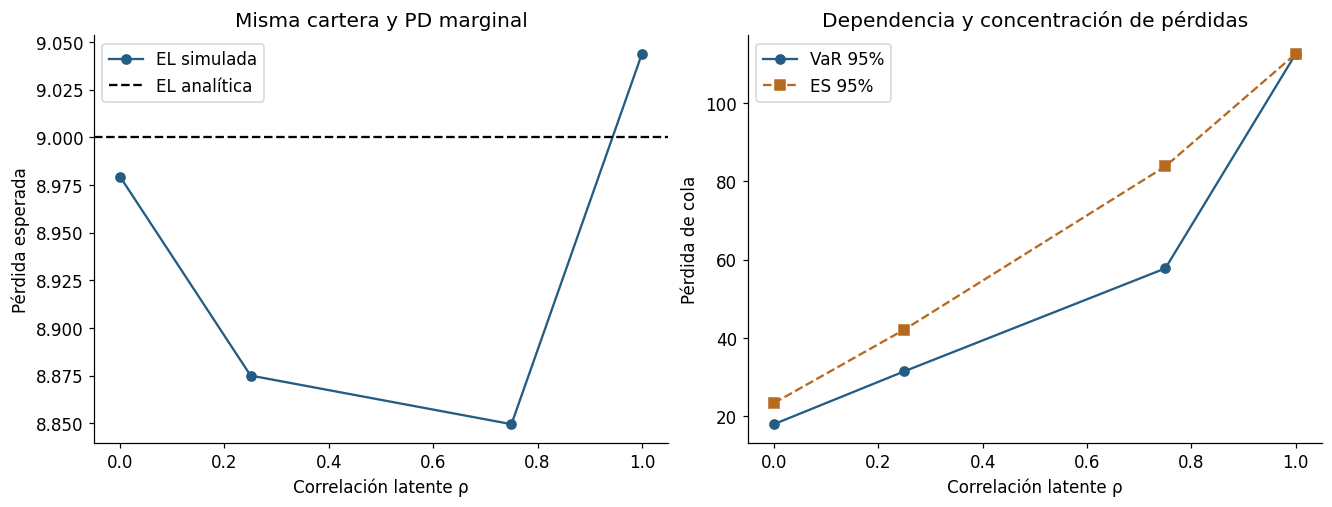

expected_loss           var95            es95        
              mean     std    mean     std    mean     std
rho                                                       
0.00        8.9792  0.0958   18.00  0.0000   23.39  0.3774
0.25        8.8750  0.1171   31.50  0.0000   42.15  1.5698
0.75        8.8495  0.3282   57.75  1.8371   83.78  1.8297
1.00        9.0438  0.4452  112.50  0.0000  112.50  0.0000

In [6]:
ead=[10.]*25;pds=[.08]*25;lgds=[.45]*25
analytic=sum(e*p*l for e,p,l in zip(ead,pds,lgds));rows=[]
for rho in [0.,.25,.75,1.]:
    for seed in range(6):
        result=models.correlated_project_losses(ead,pds,lgds,3000,SEED+seed,rho)
        rows.append(dict(rho=rho,seed=seed,analytic_EL=analytic,**result))
credit_table=pd.DataFrame(rows)
display(credit_table.groupby('rho')[['expected_loss','var95','es95']].agg(['mean','std']).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
group=credit_table.groupby('rho').mean(numeric_only=True)
axes[0].plot(group.index,group.expected_loss,'o-',label='EL simulada',color='#245C83')
axes[0].axhline(analytic,color='black',linestyle='--',label='EL analítica');axes[0].legend()
axes[0].set(xlabel='Correlación latente ρ',ylabel='Pérdida esperada',title='Misma cartera y PD marginal')
axes[1].plot(group.index,group.var95,'o-',label='VaR 95%',color='#245C83')
axes[1].plot(group.index,group.es95,'s--',label='ES 95%',color='#B56A20');axes[1].legend()
axes[1].set(xlabel='Correlación latente ρ',ylabel='Pérdida de cola',title='Dependencia y concentración de pérdidas')
plt.show()

## Migración de ES y referencia independiente
Antes, [1,2,3,4,5] con α=0.8 devolvía 4.5 al incluir el átomo VaR completo. El ES con masa exactamente 0.2 vale 5. Python, C++ y el laboratorio de mercado usan ahora la misma convención.

Las 100 fixtures se generaron con minimización racional de la representación hinge sobre todos los puntos de quiebre, una referencia independiente de integrar la cola ordenada. Las pruebas C++ consumen las mismas fixtures y siguen activas en Release.

In [7]:
count=0;max_error=0.
with (ROOT/'tests/fixtures/tail_contract.csv').open() as handle:
    for row in csv.DictReader(handle):
        loss=list(map(float,row['losses'].split(';')))
        result=models.empirical_var_es(loss,float(row['alpha']))
        max_error=max(max_error,abs(result['es']-float(row['es'])));count+=1
assert count==100 and max_error<1e-9
print('Fixtures Python contrastadas:',count,'; máximo error ES:',max_error)
print('Caso de migración:',models.empirical_var_es([1,2,3,4,5],.8))
# The model rejects bad observations instead of returning apparently valid NaN metrics.
try:models.project_finance([np.nan],[1],1)
except ValueError:print('CFADS no finito rechazado')
else:raise AssertionError('NaN aceptado')

Fixtures Python contrastadas: 100 ; máximo error ES: 2.842170943040401e-14
Caso de migración: {'var': 4.0, 'es': 5.0}
CFADS no finito rechazado


## Límites
El notebook enlaza componentes, no un gemelo digital completo de una constructora. No combina riesgo crediticio y caja sin un modelo de pérdidas coherente. Las tareas son independientes en el ejemplo, las recuperaciones crediticias son constantes, no hay inflación de materiales ni repricing endógeno, y los parámetros no fueron calibrados con proyectos reales.